<a href="https://colab.research.google.com/github/Shujaat123/COE691_XAI/blob/main/SHAP_California_Housing_Lecture_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SHAP Explained: California Housing Prices

**COE 691 · Classroom demo**

We predict the **median house value of a California census block group** (not the price of an individual house) using eight features. The original data derive from the **1990 U.S. Census**. We convert the target to **US dollars** so positive/negative SHAP values represent increases/decreases in predicted dollars relative to a baseline.

**Interpretation:** $\hat y(x)=\phi_0+\sum_j\phi_j(x)$. A SHAP contribution explains the **model output**, not causality.

**Run once if needed:** `%pip install -U numpy pandas matplotlib scikit-learn xgboost shap`

In [1]:
# 0. Imports and setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (9, 5)
shap.initjs()   # Enables interactive SHAP HTML output in Jupyter
print('SHAP version:', shap.__version__)

SHAP version: 0.54.1


## 1. Load data and train the regression model

**Question to students:** Would you expect median income, number of rooms, and location to affect predicted house values? The dataset includes geographic coordinates and census-block statistics.

In [2]:
housing = fetch_california_housing(as_frame=True)  # downloads on first use
X = housing.data.copy()
# The sklearn target is in units of $100,000; convert to dollar units.
y = housing.target * 100_000

nice_names = {
    'MedInc': 'Median income (10k USD)',
    'HouseAge': 'Median house age (years)',
    'AveRooms': 'Average rooms / household',
    'AveBedrms': 'Average bedrooms / household',
    'Population': 'Block population',
    'AveOccup': 'Average household occupancy',
    'Latitude': 'Latitude',
    'Longitude': 'Longitude',
}
X = X.rename(columns=nice_names)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
model = XGBRegressor(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    objective='reg:squarederror', random_state=RANDOM_STATE,
    n_jobs=4
)
model.fit(X_train, y_train)
pred_test = model.predict(X_test)
print(f'Train R²: {r2_score(y_train, model.predict(X_train)):.3f}')
print(f'Test  R²: {r2_score(y_test, pred_test):.3f}')
print(f'Test MAE: ${mean_absolute_error(y_test, pred_test):,.0f}')
print('Sample input:')
display(X_test.head(3))

Train R²: 0.806
Test  R²: 0.782
Test MAE: $36,563
Sample input:


,Median income (10k USD),Median house age (years),Average rooms / household,Average bedrooms / household,Block population,Average household occupancy,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01
3024,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46
15663,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44


## 2. Explain predictions with SHAP

Choose a **background sample of training rows** and a representative subset of test rows for responsive classroom plots. Because the prediction task is regression with an identity output link, SHAP values are in **US dollars**. The background set defines the expected model output used as the baseline.

In [3]:
background = X_train.sample(n=200, random_state=RANDOM_STATE)
X_demo = X_test.sample(n=300, random_state=RANDOM_STATE).copy()

# Model-agnostic entry point; recognizes tree models automatically.
explainer = shap.Explainer(model, background)
shap_values = explainer(X_demo)

print('SHAP matrix shape:', shap_values.values.shape)
print(f'Base model output: ${np.mean(shap_values.base_values):,.0f}')

# Local accuracy (additivity): baseline + feature effects ≈ prediction
reconstructed = shap_values.base_values + shap_values.values.sum(axis=1)
model_outputs = model.predict(X_demo)
max_error = np.max(np.abs(reconstructed - model_outputs))
print(f'Max reconstruction error: ${max_error:.5f}')
assert np.allclose(reconstructed, model_outputs, rtol=1e-4, atol=1.0)

SHAP matrix shape: (300, 8)
Base model output: $206,288
Max reconstruction error: $0.23057


## 3. Global importance — bar chart

Features are ranked by average **absolute** impact across the 300 explained neighborhoods. This summarizes strength but not direction.

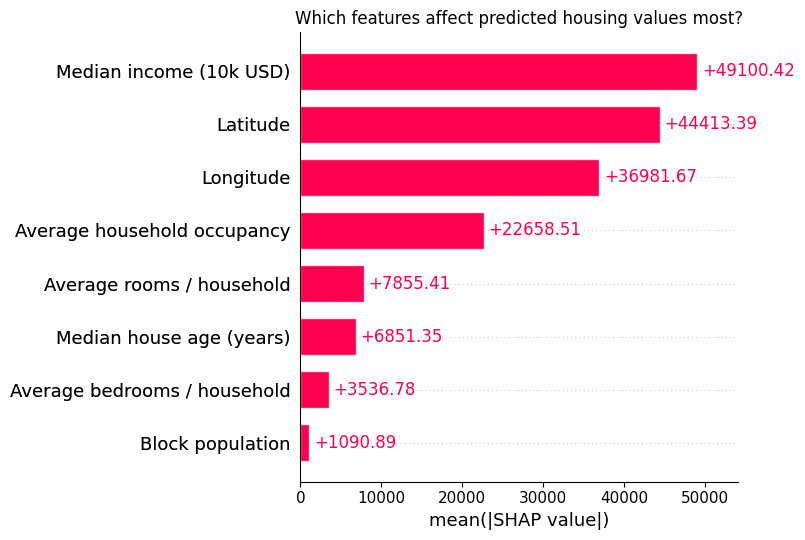

In [4]:
shap.plots.bar(shap_values, max_display=8, show=False)
plt.title('Which features affect predicted housing values most?')
plt.tight_layout()
plt.show()

## 4. Global explanation — beeswarm

Each dot is a neighborhood. **Horizontal position** indicates the SHAP effect in dollars; **color** indicates whether the feature is high or low for that neighborhood. A high value is not automatically associated with a positive effect.

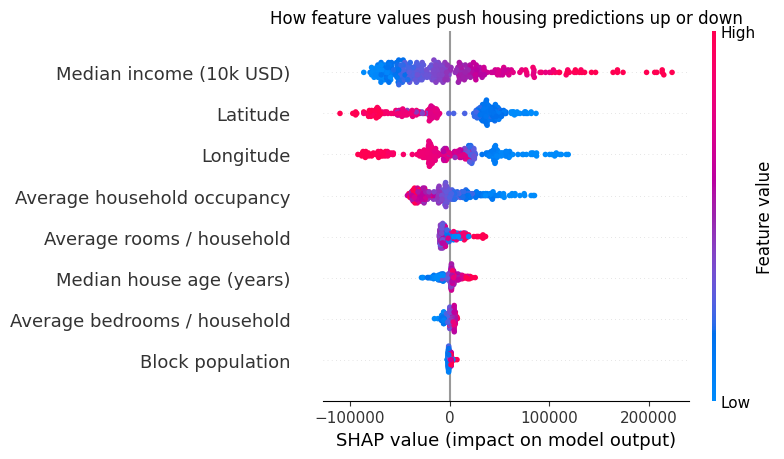

In [5]:
shap.plots.beeswarm(shap_values, max_display=8, show=False)
plt.title('How feature values push housing predictions up or down')
plt.tight_layout()
plt.show()

## 5. Dependence plot — median income

Shows how the contribution of median income varies across neighborhoods. The vertical spread at the same income can reflect interactions with other variables.

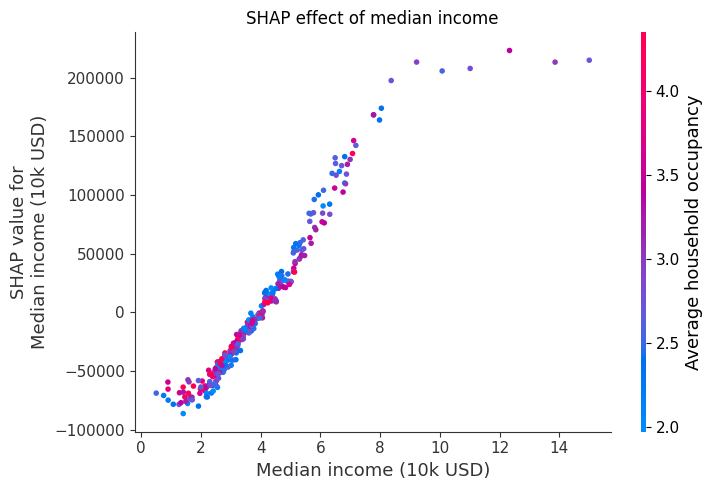

In [6]:
shap.dependence_plot(
    'Median income (10k USD)',
    shap_values.values,
    X_demo,
    feature_names=list(X_demo.columns),
    interaction_index='auto',
    show=False,
)
plt.title('SHAP effect of median income')
plt.tight_layout()
plt.show()

## 6. Local explanation — force plot

**Red** contributions push the prediction *up* relative to the baseline; **blue** contributions push it *down*. These directions mean higher/lower **housing value**, not malignant/benign or class likelihood.

In [7]:
idx = 0  # Change to inspect a different neighborhood
sample_explanation = shap_values[idx]
base_value = float(sample_explanation.base_values)
model_prediction = float(model.predict(X_demo.iloc[[idx]])[0])
print(f'Baseline prediction: ${base_value:,.0f}')
print(f'Predicted house value: ${model_prediction:,.0f}')
print(f'Sum of SHAP values: ${sample_explanation.values.sum():,.0f}')

display(shap.force_plot(
    base_value,
    sample_explanation.values,
    sample_explanation.data,
    feature_names=list(X_demo.columns)
))

Baseline prediction: $206,288
Predicted house value: $305,191
Sum of SHAP values: $98,903


## 7. Local explanation — waterfall plot

Starts from the baseline, adds or subtracts each feature attribution, and ends at the predicted block-group median value.

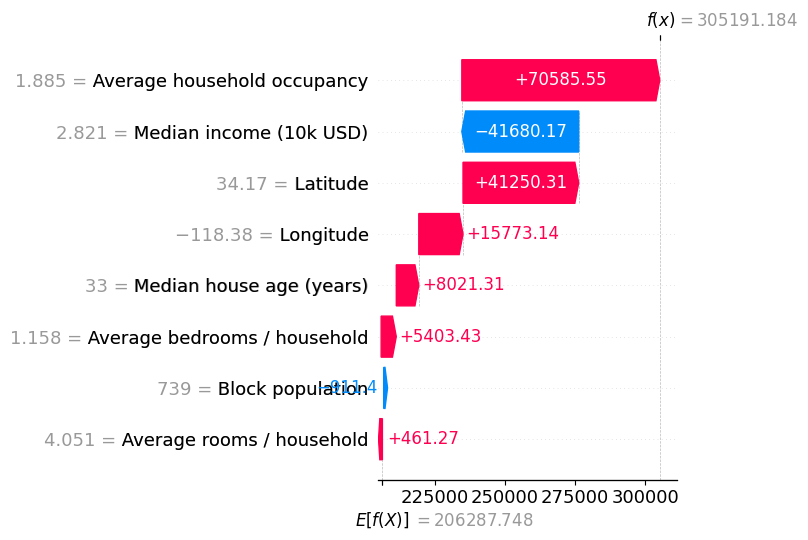

In [8]:
shap.plots.waterfall(shap_values[idx], max_display=8, show=False)
plt.tight_layout()
plt.show()

## 8. Decision plot — many neighborhoods

Each line represents a separate neighborhood. Trace how adding features shifts the prediction away from the common baseline.

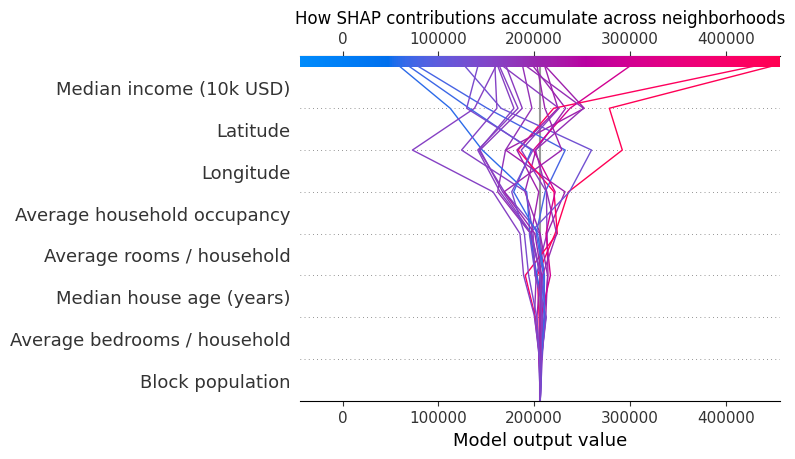

In [9]:
subset_idx = rng.choice(len(X_demo), size=20, replace=False)
subset_shap = shap_values[subset_idx]
# The selected rows share a fixed background baseline.
base_for_decision = float(np.mean(subset_shap.base_values))
shap.decision_plot(
    base_value=base_for_decision,
    shap_values=subset_shap.values,
    features=X_demo.iloc[subset_idx],
    feature_names=list(X_demo.columns),
    show=False,
)
plt.title('How SHAP contributions accumulate across neighborhoods')
plt.tight_layout()
plt.show()

## 9. Board discussion: verify one prediction
Calculate: **baseline + all feature contributions = prediction**. Comparing positive and negative effects is more interpretable than looking only at global feature importance.

In [10]:
one = shap_values[idx]
contributions = pd.Series(one.values, index=X_demo.columns)
contrib_table = pd.DataFrame({
    'Feature value': X_demo.iloc[idx],
    'SHAP contribution ($)': contributions,
}).sort_values('SHAP contribution ($)', key=lambda col: col.abs(), ascending=False)
display(contrib_table.round(2))
print(f"Base: ${float(one.base_values):,.2f}")
print(f"Sum of SHAP effects: ${contributions.sum():+,.2f}")
print(f"Reconstructed: ${float(one.base_values) + contributions.sum():,.2f}")
print(f"Model prediction: ${model_prediction:,.2f}")

,Feature value,SHAP contribution ($)
Average household occupancy,1.89,70585.55
Median income (10k USD),2.82,-41680.17
Latitude,34.17,41250.31
Longitude,-118.38,15773.14
Median house age (years),33.00,8021.31
Average bedrooms / household,1.16,5403.43
Block population,739.00,-911.40
Average rooms / household,4.05,461.27


Base: $206,287.75
Sum of SHAP effects: $+98,903.44
Reconstructed: $305,191.18
Model prediction: $305,191.06
